> **Generated** from [`telablur_notebook.py`](../telablur_notebook.py) by `scripts/build_ipynb.py`: don't edit this file.

In [ ]:
# cell: client
# Shared scaffolding, generated from client.py by scripts/sync_client.py: edit client.py, not this block.
# Only the public helpers are visible to other cells; import any module you use in your own cells.
# Imported under private names so a notebook's setup cell exposes only the public helpers (and the module
# names stay free for the notebook's own imports, as they would be with `from moth_atlas import ...`).
import hashlib as _hashlib
import mimetypes as _mimetypes
import os as _os
import time as _time
from pathlib import Path as _Path

import requests as _requests


_session = _requests.Session()
_session.headers["User-Agent"] = "atlas-engine-notebooks"


def _call(method, path, **kw):
    # Env is read per call, so a key exported after import still takes effect.
    base = _os.environ.get("MOTH_API_BASE", "https://api.mothquantum.com").rstrip("/")
    key = _os.environ.get("MOTH_API_KEY", "")
    if not key:
        raise RuntimeError("MOTH_API_KEY is not set: create a key on the Atlas API keys page and export it")
    r = _session.request(method, f"{base}/api/v1{path}", headers={"Authorization": f"Bearer {key}"}, timeout=30, **kw)
    if r.status_code >= 400:  # keep the API's error body; raise_for_status() would drop it
        raise RuntimeError(f"{method} {path} -> {r.status_code}: {r.text[:300]}")
    return r.json() if r.content else None


def _presigned(method, url, **kw):
    # Presigned URLs carry their own signature: never send the API key to them (plain requests, not _session).
    r = _requests.request(method, url, timeout=60, **kw)
    if r.status_code >= 400:
        raise RuntimeError(f"{method} presigned URL -> {r.status_code}: {r.text[:300]}")
    return r


_uploaded = {}  # (sha256, content_type) -> asset_id, so re-running a cell doesn't re-upload


def upload(file: str | _os.PathLike | bytes, content_type: str | None = None, filename: str | None = None) -> str:
    """Upload a file path or raw bytes; returns its asset id.

    content_type defaults to a guess from the filename; filename names uploaded bytes.
    Runs the three API steps: create, PUT to the presigned URL, complete."""
    if isinstance(file, (bytes, bytearray)):
        data, filename = bytes(file), filename or "file"
    else:
        data, filename = _Path(file).read_bytes(), filename or _Path(file).name
    content_type = content_type or _mimetypes.guess_type(filename)[0] or "application/octet-stream"
    key = (_hashlib.sha256(data).hexdigest(), content_type)
    if key not in _uploaded:
        asset = _call("POST", "/assets", json={"filename": filename, "content_type": content_type, "size_bytes": len(data)})
        up = asset["upload"]
        _presigned(up.get("method", "PUT"), up["url"], data=data, headers=up["headers"])
        _uploaded[key] = _call("POST", f"/assets/{asset['asset_id']}/complete")["asset_id"]
    return _uploaded[key]


def submit(engine: str, params: dict, input_files: dict[str, str] | None = None) -> str:
    """Start a job on an engine; returns its job id. params is a dict of the engine's parameters; input_files is a dict mapping each input slot name to an asset id."""
    body = {"params": params, **({"input_files": input_files} if input_files else {})}
    return _call("POST", f"/engines/{engine}/process", json=body)["job_id"]


def wait(job_id: str, interval: float = 1.5, timeout: float = 600, on_update=None) -> None:
    """Block until the job completes, checking every interval seconds; raises if it fails, is cancelled, or takes longer than timeout seconds.

    on_update(job) is called whenever the status changes, with the status response as a dict,
    e.g. on_update=lambda job: print(job["status"])."""
    deadline, last = _time.monotonic() + timeout, None
    while _time.monotonic() < deadline:
        job = _call("GET", f"/jobs/{job_id}/status")
        if on_update and job["status"] != last:
            on_update(job)
            last = job["status"]
        if job["status"] == "completed":
            return
        if job["status"] in ("failed", "cancelled"):
            raise RuntimeError(f"Job {job_id} {job['status']}: {job.get('error')}")
        _time.sleep(interval)
    raise TimeoutError(f"Job {job_id} did not finish in {timeout}s")


def download(job_id: str, slot: str = "result") -> bytes | dict:
    """Return a finished job's output: the bytes of the file in slot (or the first output), or the inline JSON result (a dict) for engines that produce no file."""
    res = _call("GET", f"/jobs/{job_id}/result")
    outputs = res.get("outputs") or []
    out = next((o for o in outputs if o.get("slot") == slot), outputs[0] if outputs else None)
    if out is None:
        if res.get("result") is None:
            raise RuntimeError(f"Job {job_id} finished without an output")
        return res["result"]
    url = out.get("url") or _call("GET", f"/assets/{out['output_asset_id']}/download")["download_url"]
    return _presigned("GET", url).content

In [ ]:
# cell: setup
# Import every module your cells use here; the hidden block at the top provides only the API helpers.
import marimo as mo

Quantum Teleblur morphs one image into another through qubit rotations.

## Try it

Drop a source and a target image (or leave them empty to use the samples), pick the parameters, then press **Run**.

In [ ]:
# cell: engine
# upload, submit, wait and download: the Moth API helpers, from the hidden block at the top.
ENGINE_ID = "telablur-v1"

def run_engine(params, files):
    """Run one job. files maps each input slot to its (bytes, filename); returns the output image's bytes."""
    input_files = {slot: upload(data, filename=name) for slot, (data, name) in files.items()}
    job_id = submit(ENGINE_ID, params, input_files)
    wait(job_id)
    return download(job_id)

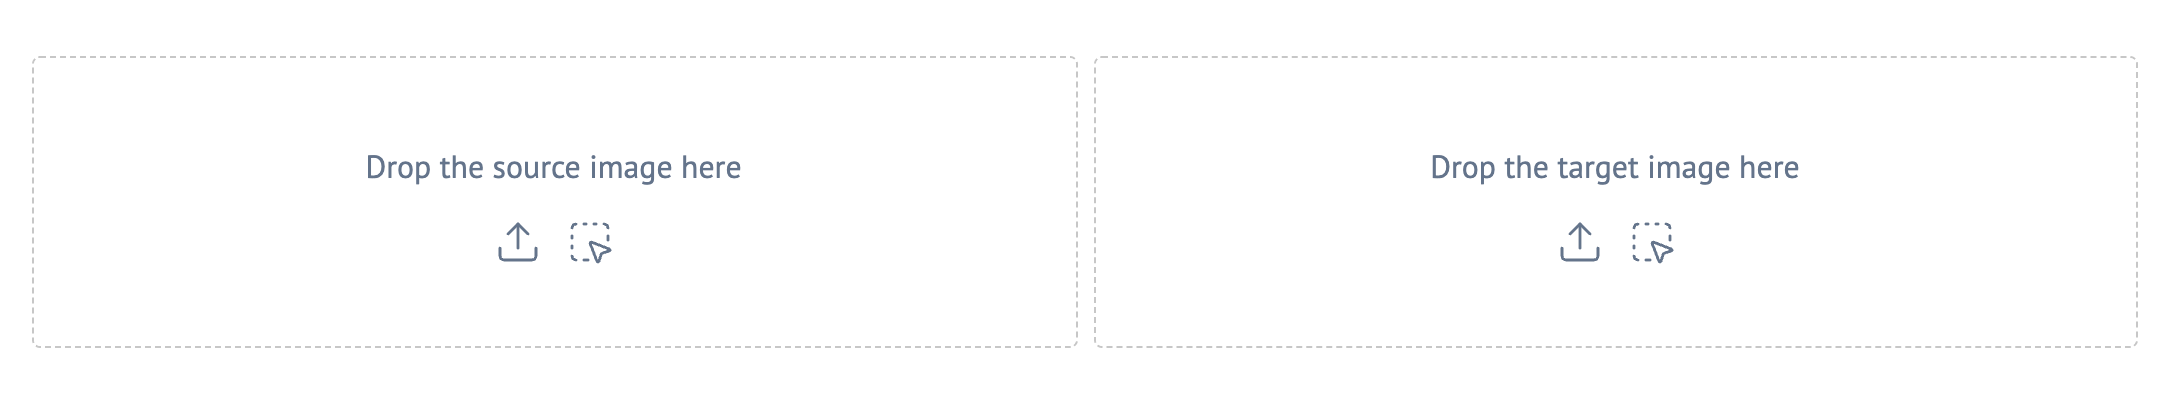

In [ ]:
# cell: inputs
IMAGE_TYPES = [".png", ".jpg", ".jpeg", ".webp", ".tiff", ".bmp"]
SAMPLE1, SAMPLE2 = mo.notebook_dir() / "image1.png", mo.notebook_dir() / "image2.png"
picker1 = mo.ui.file(filetypes=IMAGE_TYPES, kind="area", label="Drop the source image here")
picker2 = mo.ui.file(filetypes=IMAGE_TYPES, kind="area", label="Drop the target image here")
mo.hstack([picker1, picker2], widths="equal")

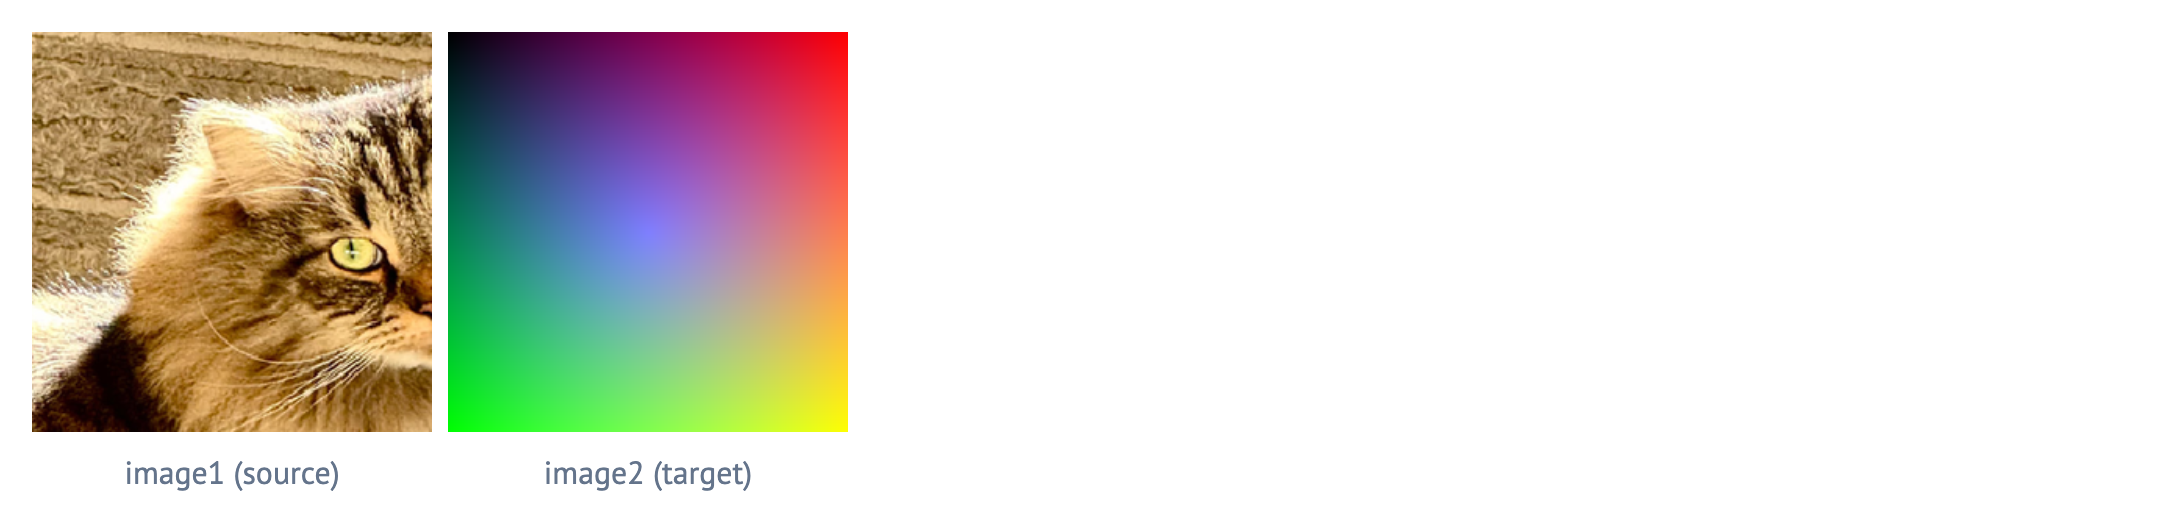

In [ ]:
# cell: images
# Each upload, or its sample when nothing is uploaded.
def pick(picker, sample):
    return (picker.contents(), picker.name()) if picker.value else (sample.read_bytes(), sample.name)

image1_bytes, image1_name = pick(picker1, SAMPLE1)
image2_bytes, image2_name = pick(picker2, SAMPLE2)
files = {"image1": (image1_bytes, image1_name), "image2": (image2_bytes, image2_name)}
mo.hstack([
    mo.image(image1_bytes, width=200, caption="image1 (source)"),
    mo.image(image2_bytes, width=200, caption="image2 (target)"),
], justify="start")

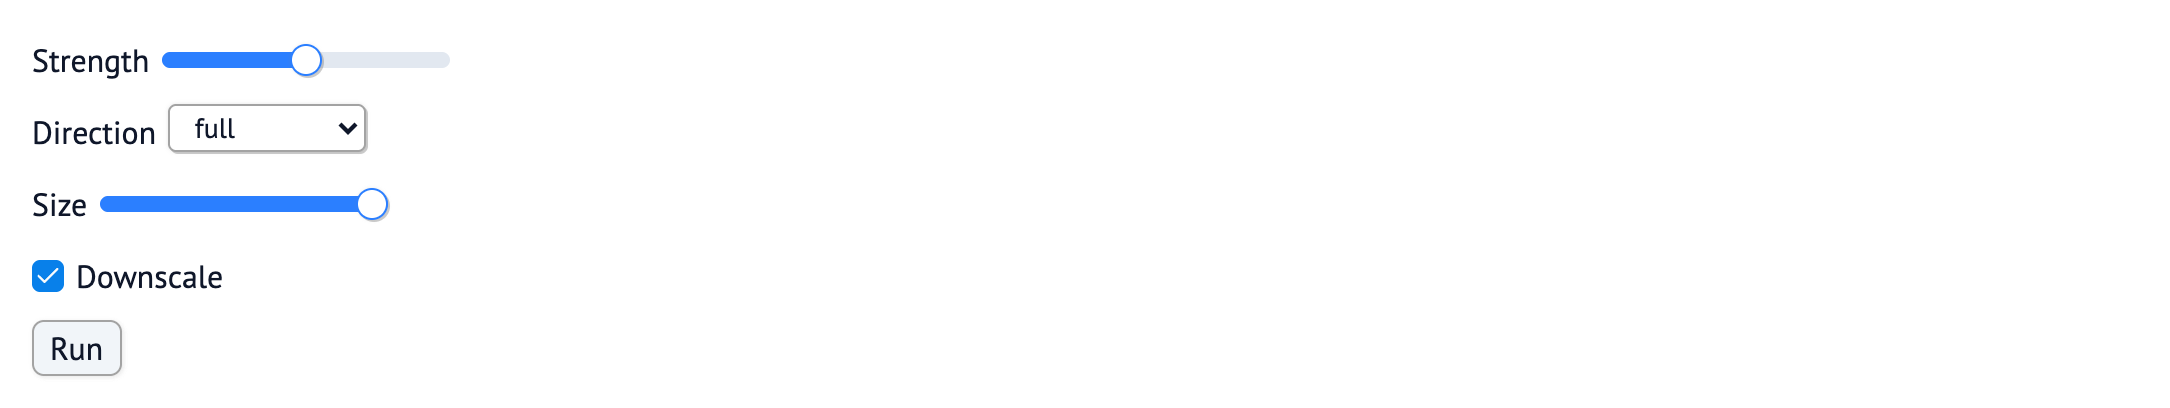

In [ ]:
# cell: params
# Keys are the engine's parameter names, so params.value is the dict sent to the API.
params = mo.ui.dictionary({
    "strength": mo.ui.slider(0, 1, step=0.05, value=0.5, label="Strength"),
    "direction": mo.ui.dropdown(["full", "vertical", "horizontal"], value="full", label="Direction"),
    "size": mo.ui.slider(8, 1024, step=8, value=1024, label="Size"),
    "downscale": mo.ui.checkbox(value=True, label="Downscale"),
})
run = mo.ui.run_button(label="Run")
mo.vstack([params.vstack(), run])

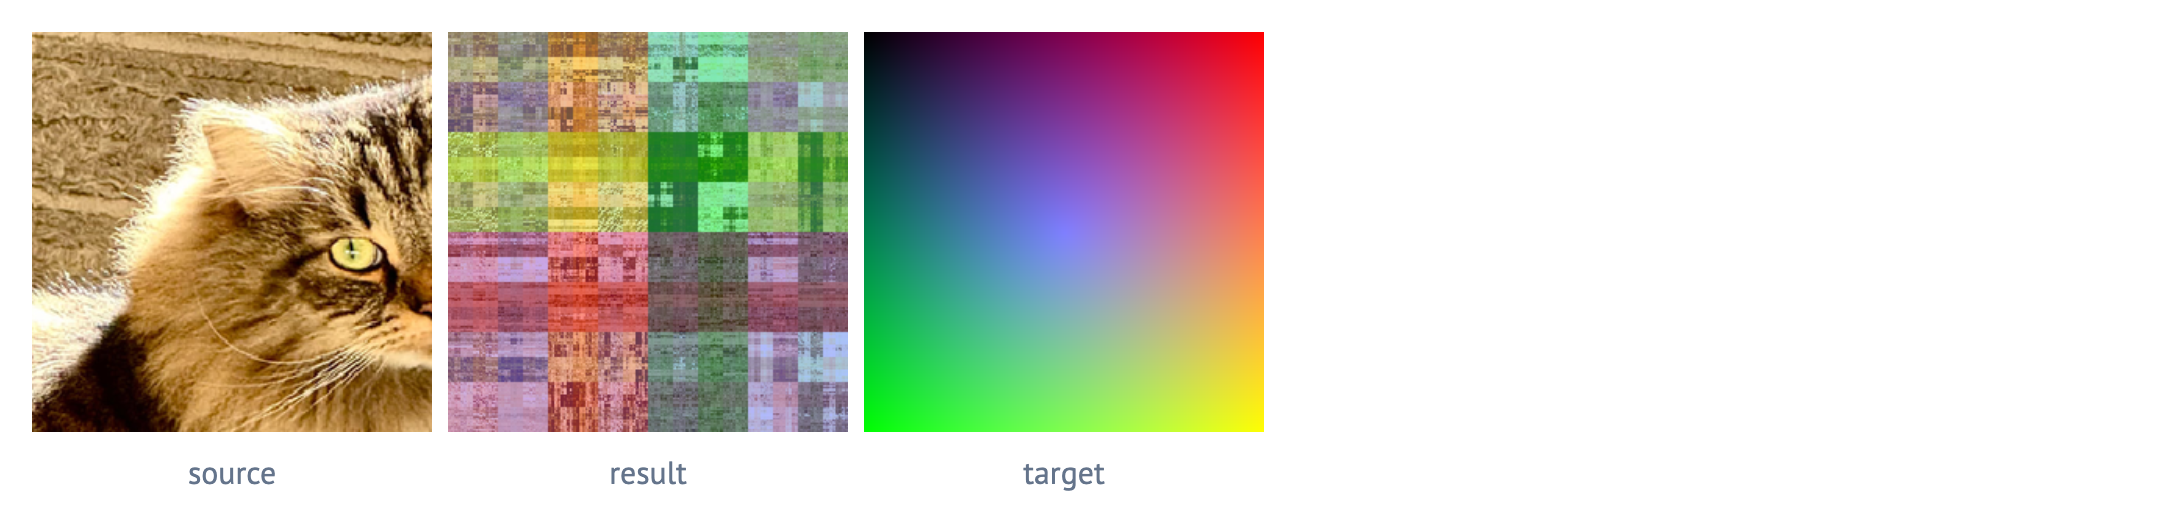

In [ ]:
# cell: run
mo.stop(not run.value, mo.md("Press **Run** to see the result."))
result = run_engine(params.value, files)
mo.hstack([
    mo.image(image1_bytes, width=200, caption="source"),
    mo.image(result, width=200, caption="result"),
    mo.image(image2_bytes, width=200, caption="target"),
], justify="start")

## Parameters

| name | type | default | what it does |
|---|---|---|---|
| `image1` (input file) | PNG, JPEG, WebP, TIFF or BMP | required | The source image. It is morphed toward `image2`. |
| `image2` (input file) | PNG, JPEG, WebP, TIFF or BMP | required | The target image. It is resized to match `image1` if the dimensions differ. |
| `mask` (input file) | PNG, JPEG, WebP, TIFF or BMP | optional | Per-pixel strength of the effect: black keeps `image1` unchanged, white applies the full effect. If omitted, `image1`'s alpha channel is used. |
| `strength` | float, 0 to 1 | 0.5 | Strength of the teleportation effect. |
| `direction` | `full`, `vertical` or `horizontal` | `full` | Which qubits get the blur rotation: `full` rotates all pixel qubits; `vertical` and `horizontal` limit the blur to one axis. |
| `size` | integer, 8 to 1024 | 1024 | Pixel budget per pass: a region up to `size × size` pixels is teleported in a single pass. |
| `downscale` | boolean | true | If true, oversized regions are downscaled before teleport and upscaled back; if false, they are tiled into sub-images. |
| `mask_bin_size` | number, 0 to 100 | 4 | Mask quantisation step as a percentage of 255. |
| `mask_min_region` | integer, at least 1 | 16 | Minimum connected mask region size in pixels; smaller regions are discarded. |

**Returns:** the processed image.

## How it works

Both images are encoded into one quantum state on $n+1$ qubits: $n$ qubits for the pixels and one selector qubit that marks which image each amplitude belongs to. Rotating the selector qubit blends the two images at the amplitude level.

## Experiments

Each experiment changes one parameter and keeps the others fixed. Press its button to run it.

### Strength

Strength of the teleportation effect, from `image1` unchanged at 0 to the full effect at 1.

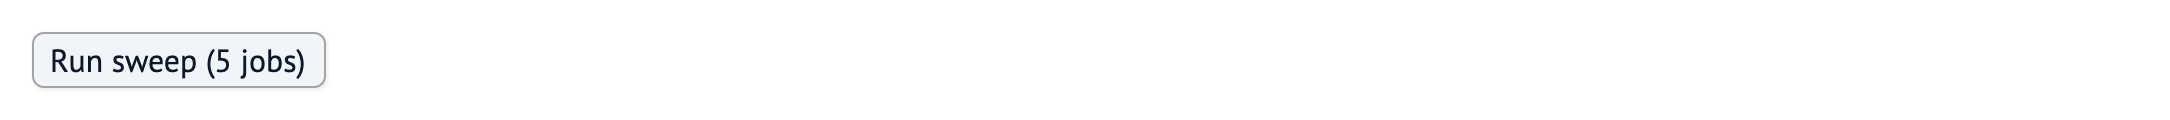

In [ ]:
# cell: strength-params
# Edit the values, then press the button: one job per value.
STRENGTHS = (0.0, 0.25, 0.5, 0.75, 1.0)
run_strength = mo.ui.run_button(label=f"Run sweep ({len(STRENGTHS)} jobs)")
run_strength

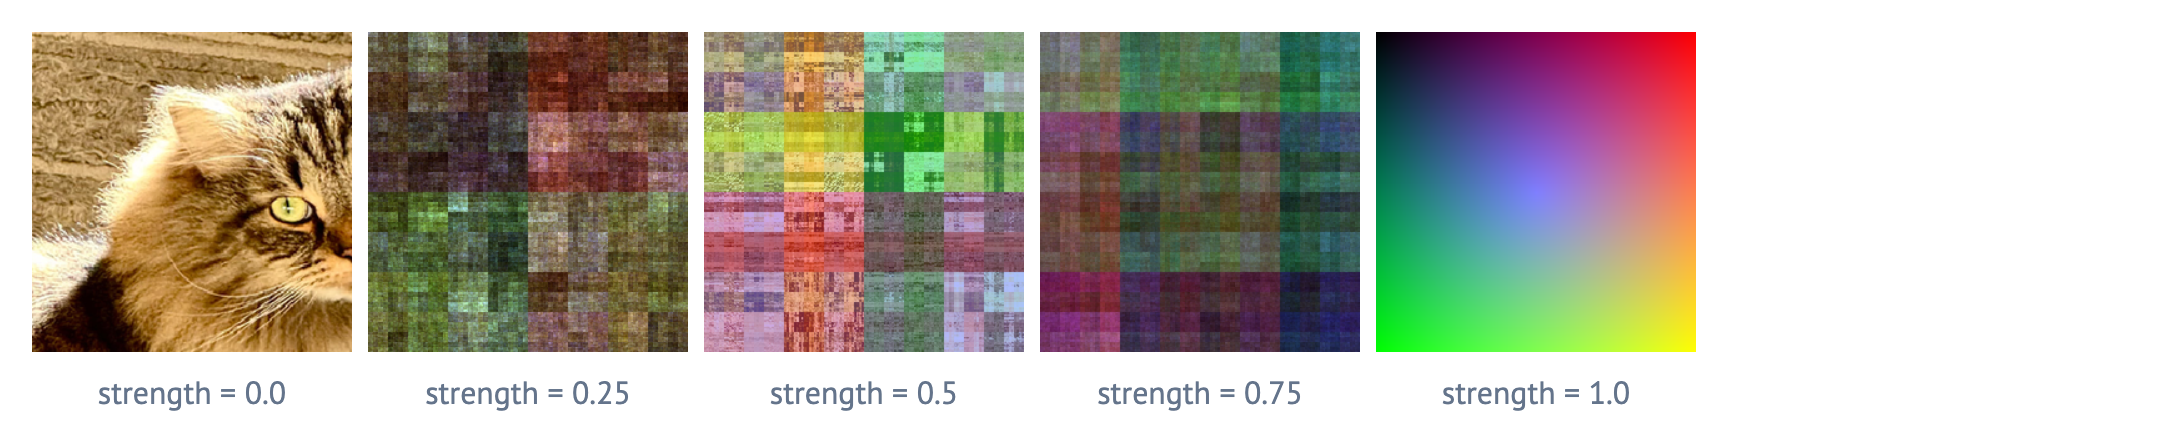

In [ ]:
# cell: strength
mo.stop(not run_strength.value, mo.md("Press **Run sweep** to compare the values above."))
tiles = [
    mo.image(run_engine({**params.value, "strength": s}, files), width=160, caption=f"strength = {s}")
    for s in STRENGTHS
]
mo.hstack(tiles, wrap=True, justify="start")

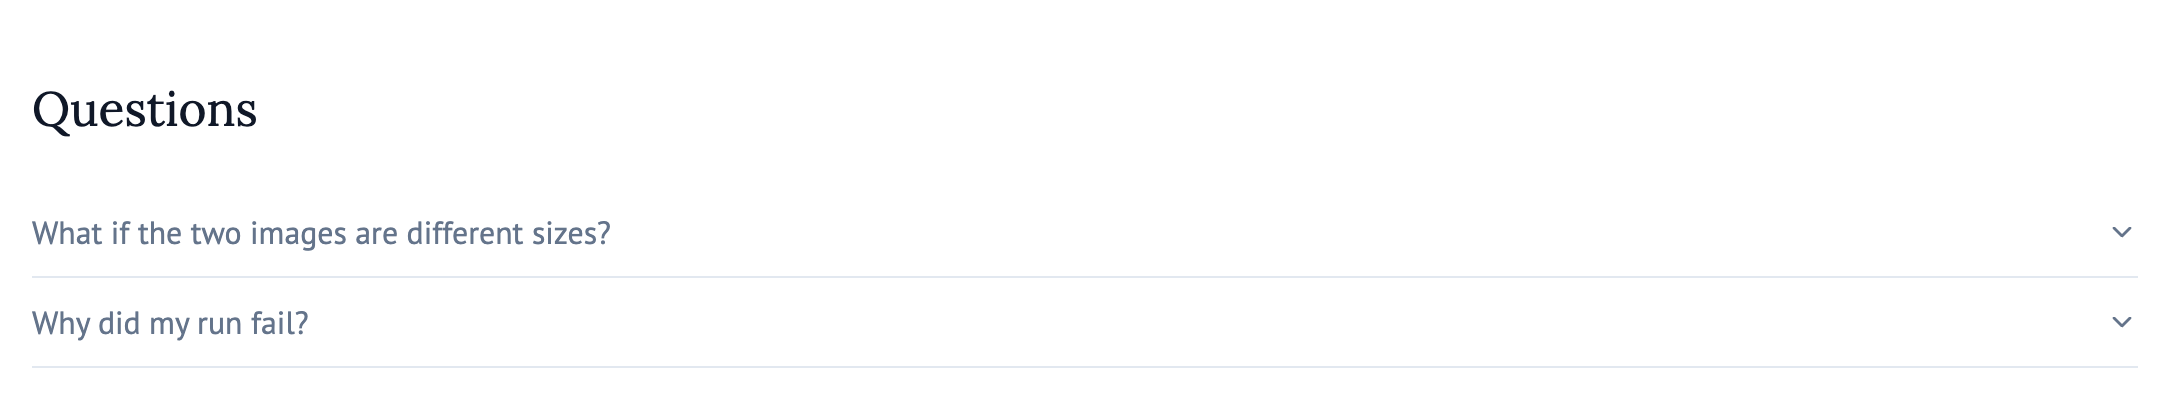

In [ ]:
# cell: questions
mo.vstack([mo.md("## Questions"), mo.accordion({
    "What if the two images are different sizes?": "image2 is resized to match image1.",
    "Why did my run fail?": "A run still going after 18,000 s is cancelled and the job ends failed. Mismatched mask sizes and masks with no non-zero pixels are rejected.",
})])